# DLS notebook guide

The original comparison workflow loads two `.exp` files, lists their measurements and phases, reads the raw `c1` correlation curves and delay-time arrays, smooths and normalizes each curve, and calculates the half-decay lag time (`tau_half`). It then compares that value over experiment time and temperature and plots individual and median correlation curves. Its input paths are machine-specific, and it does not calculate polydispersity or particle diameter.

The final section added for this dataset uses `analyze_dls.py` to process the four measurements in `20261103_3HAE-annealed_notsure5htb.exp`. It overlays accepted PDI estimates against acquisition time, reports median estimated hydrodynamic diameter per sample, and adds a diameter-versus-PDI scatter plot. The four legend labels are 25 °C 3H-AE, 25 °C 5HT-B, 37 °C 5HT-B, and 37 °C 3H-AE. The scatter includes all 40 calculable acquisitions per sample; circles passed fit checks and `x` markers identify rejected fits; out-of-range PDI values are clipped to the plot boundaries.

**Interpretation:** the file contains raw correlation curves, not populated PDI/diameter results. These are estimates, not instrument-reported values. The workflow assumes delay times are seconds, 90-degree scattering, refractive index 1.333, and aqueous KCl viscosity approximated by water. Median diameters are calculated from fits passing the R-squared and PDI checks; excluded but calculable fits are retained in the scatter for acquisition-level context. Verify the instrument geometry and lag-time units before using the sizes quantitatively.

In [ ]:
# ============================================================
# DLS Analysis
# Author: AJH
# ============================================================

# --- Imports ---
import os
import re
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as mplcm
import seaborn as sns
from scipy.ndimage import uniform_filter1d
from mpl_toolkits.axes_grid1 import Divider, Size
from matplotlib.transforms import Bbox

# --- Figure size helper ---
cm = 1/2.54

# --- Default DPI ---
plt.rcParams['figure.dpi'] = 150

WORKING_DIR = Path.cwd().resolve()
DLS_DIR = next(
    (candidate for root in [WORKING_DIR, *WORKING_DIR.parents]
     for candidate in (root / "DLS", root / "origami_data" / "DLS", root)
     if (candidate / "analyze_dls.py").is_file()),
    None,
)
if DLS_DIR is None:
    raise FileNotFoundError(f"Could not locate DLS/analyze_dls.py from {WORKING_DIR}")
PLOT_DIR = DLS_DIR / "plots" / "AJH_v4_comparison"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

_original_show = plt.show
_saved_figures = set()
_plot_counter = 0

def _show_and_save(*args, **kwargs):
    global _plot_counter
    for number in plt.get_fignums():
        figure = plt.figure(number)
        if figure in _saved_figures:
            continue
        titles = [axis.get_title() for axis in figure.axes if axis.get_title()]
        label = figure._suptitle.get_text() if figure._suptitle else "_".join(titles)
        slug = re.sub(r"[^A-Za-z0-9._-]+", "_", label).strip("_.-").lower()
        _plot_counter += 1
        filename = f"{_plot_counter:02d}_{slug or 'plot'}.png"
        figure.savefig(PLOT_DIR / filename, dpi=180, bbox_inches="tight")
        _saved_figures.add(figure)
    return _original_show(*args, **kwargs)

plt.show = _show_and_save
print(f"Plots will be saved to: {PLOT_DIR}")

In [31]:
# --- Load the .exp files ---
# Two independent samples / measurements — both are treated equally
# (no sample is used as a buffer reference)

# --- Sample 1 ---
file_path_1 = r"C:\Users\ge57xix\OneDrive\TUM\3. PhD\1. Research\Python\data\260713_Measure_unfolded_ROOL-Lsa_Data.exp"

# --- Sample 2 ---
file_path_2 = r"C:\Users\ge57xix\OneDrive\TUM\3. PhD\1. Research\Python\data\260521_Measure_folded_RNA_500nM.exp"

# --- Legend labels ---
# Set to 'auto' to use the filename, or provide a custom short label
LABEL_1 = 'auto'
LABEL_2 = 'auto'

source_name_1 = os.path.splitext(os.path.basename(file_path_1))[0]
source_name_2 = os.path.splitext(os.path.basename(file_path_2))[0]

with open(file_path_1, 'r', encoding='latin-1') as f:
    rawfile_1 = f.readlines()
print(f"Sample 1 loaded: {len(rawfile_1)} lines found")
print(f"Source: {source_name_1}")

with open(file_path_2, 'r', encoding='latin-1') as f:
    rawfile_2 = f.readlines()
print(f"\nSample 2 loaded: {len(rawfile_2)} lines found")
print(f"Source: {source_name_2}")

# --- Combined datasets dictionary ---
datasets = {
    'sample_1': {'rawfile': rawfile_1, 'source_name': source_name_1, 'phase_filter': None},
    'sample_2': {'rawfile': rawfile_2, 'source_name': source_name_2, 'phase_filter': None},
}
# phase_filter is set in the 'Phase filter' cell below (after the overview)

# Sample keys and display labels — used by all following cells
sample_keys   = list(datasets.keys())
sample_labels = {
    'sample_1': source_name_1 if LABEL_1 == 'auto' else LABEL_1,
    'sample_2': source_name_2 if LABEL_2 == 'auto' else LABEL_2,
}

print(f"\nDatasets ready: {sample_keys}")

Sample 1 loaded: 4099 lines found
Source: 260713_Measure_unfolded_ROOL-Lsa_Data

Sample 2 loaded: 11707 lines found
Source: 260521_Measure_folded_RNA_500nM

Datasets ready: ['sample_1', 'sample_2']


In [32]:
# --- Build measurement lookup for both files ---
# This cell also lists which measurements / phases each file contains,
# so the phase filter in the next cell can be set accordingly

lookups           = {}  # stores measurement_lookup per sample
available_phases  = {}  # stores the phase names found per sample

for sample, data in datasets.items():
    rawfile = data['rawfile']
    measurement_lookup = {}

    i = 0
    while i < len(rawfile):
        line = rawfile[i].strip()

        if line.startswith('[Measurement '):
            meas_num = int(line.replace('[Measurement ', '').replace(']', ''))
            meas_data = {'name': None, 'data_rows': {}}

            j = i + 1
            while j < len(rawfile):
                l = rawfile[j].strip()

                if l.startswith('[Measurement '):
                    break
                if l.startswith('[Acquisition ') and l.endswith(' 1]'):
                    parts = l.replace('[Acquisition ', '').replace(']', '').split(' ')
                    if int(parts[0]) != meas_num:
                        break

                if l.startswith('Name=') and 'Meas' not in l:
                    meas_data['name'] = l.replace('Name=', '')

                if l.startswith('Data Row ') and '=' in l and 'Acq' in l:
                    try:
                        row_num = int(l.split('=')[0].replace('Data Row ', ''))
                        parts = l.split('|')
                        time_val = float(parts[6].replace('$0$0', '').strip())
                        temp_val = float(parts[7].replace('$0$0', '').strip())
                        meas_data['data_rows'][row_num] = {'time': time_val, 'temp': temp_val}
                    except:
                        pass

                j += 1

            measurement_lookup[meas_num] = meas_data
            i = j
        else:
            i += 1

    lookups[sample] = measurement_lookup

    # Summary output
    lookup_phase_order = []
    lookup_phase_count = {}   # acquisitions per phase
    lookup_phase_meas  = {}   # measurements per phase
    for meas_num in sorted(measurement_lookup.keys()):
        name = measurement_lookup[meas_num]['name']
        if name is None:
            continue
        phase = name.split('_')[0]
        n_acqs = len(measurement_lookup[meas_num]['data_rows'])
        if phase not in lookup_phase_count:
            lookup_phase_order.append(phase)
            lookup_phase_count[phase] = 0
            lookup_phase_meas[phase]  = 0
        lookup_phase_count[phase] += n_acqs
        lookup_phase_meas[phase]  += 1

    print(f"\n{sample.upper()} — {data['source_name']}")
    print(f"Total measurements: {len(measurement_lookup)}")
    print(f"Total acquisitions: {sum(lookup_phase_count.values())}")
    print(f"\n{'Phase':<20} {'Measurements':>13} {'Acquisitions':>13}")
    print("-" * 48)
    for phase in lookup_phase_order:
        print(f"{phase:<20} {lookup_phase_meas[phase]:>13} {lookup_phase_count[phase]:>13}")

    # Store the phases found in this file — used by the phase filter cell
    available_phases[sample] = lookup_phase_order

    # Full measurement names, so the phase names can be checked against the source
    print(f"\nMeasurement names:")
    for meas_num in sorted(measurement_lookup.keys()):
        name = measurement_lookup[meas_num]['name']
        if name is None:
            continue
        print(f"  [{meas_num}] {name}  ({len(measurement_lookup[meas_num]['data_rows'])} acq)")

# --- Overview: which phases are available per sample ---
print("\n" + "=" * 60)
print("Available phases — copy the ones you want into the phase filter cell")
print("=" * 60)
for sample in sample_keys:
    print(f"{sample} ({sample_labels[sample]}):")
    print(f"  {available_phases[sample]}")


SAMPLE_1 — 260713_Measure_unfolded_ROOL-Lsa_Data
Total measurements: 1
Total acquisitions: 40

Phase                 Measurements  Acquisitions
------------------------------------------------
200nM                            1            40

Measurement names:
  [1] 200nM_23.5C_1.2e+003s_1  (40 acq)

SAMPLE_2 — 260521_Measure_folded_RNA_500nM
Total measurements: 3
Total acquisitions: 120

Phase                 Measurements  Acquisitions
------------------------------------------------
200nM                            1            40
350nM                            1            40
500nM                            1            40

Measurement names:
  [1] 200nM_23.6C_1.22e+003s_1  (40 acq)
  [2] 350nM_23.5C_2.99e+003s_2  (40 acq)
  [3] 500nM_23.5C_4.73e+003s_3  (40 acq)

Available phases — copy the ones you want into the phase filter cell
sample_1 (260713_Measure_unfolded_ROOL-Lsa_Data):
  ['200nM']
sample_2 (260521_Measure_folded_RNA_500nM):
  ['200nM', '350nM', '500nM']


In [57]:
# --- Phase filter: choose which measurements to keep per sample ---
# A file can contain several measurements (e.g. a whole session with multiple samples).
# The phase is the part of the measurement name before the first '_'
# (e.g. 'Name=CryoEM-Buffer_23.5C_1.24e+003s_1' -> phase 'CryoEM-Buffer').
# Copy the phase names from the overview printed by the cell above.
# Set to None to keep all phases of that file.

PHASE_FILTER_1 = None                    # e.g. ['20-90C', '90-20C']
PHASE_FILTER_2 = ['200nM']       # e.g. keep only the buffer measurements

# --- Apply and validate ---
phase_filters = {'sample_1': PHASE_FILTER_1, 'sample_2': PHASE_FILTER_2}

for sample in sample_keys:
    phase_filter = phase_filters[sample]
    datasets[sample]['phase_filter'] = phase_filter

    # Warn about phase names that do not exist in this file (typos)
    if phase_filter is not None:
        unknown = [p for p in phase_filter if p not in available_phases[sample]]
        if unknown:
            print(f"⚠️  {sample}: phase(s) not found in file: {unknown}")
            print(f"    available: {available_phases[sample]}")

    kept = available_phases[sample] if phase_filter is None else \
           [p for p in available_phases[sample] if p in phase_filter]
    dropped = [p for p in available_phases[sample] if p not in kept]

    print(f"\n{sample} ({sample_labels[sample]})")
    print(f"  keep:  {kept}")
    print(f"  drop:  {dropped if dropped else '—'}")


sample_1 (260713_Measure_unfolded_ROOL-Lsa_Data)
  keep:  ['200nM']
  drop:  —

sample_2 (260521_Measure_folded_RNA_500nM)
  keep:  ['200nM']
  drop:  ['350nM', '500nM']


In [58]:
# --- Read all raw correlation curves into DataFrames ---
# Single pass through each file
# Accepts both c1=399| and c1=400| blocks — always uses first 399 values

raw_rows_all = []

for sample, data in datasets.items():
    rawfile          = data['rawfile']
    measurement_lookup = lookups[sample]
    raw_rows         = []

    i = 0
    while i < len(rawfile):
        line = rawfile[i].strip()

        if line.startswith('[Acquisition '):
            parts    = line.replace('[Acquisition ', '').replace(']', '').split(' ')
            meas_num = int(parts[0])
            acq_num  = int(parts[1])

            meas_info = measurement_lookup.get(meas_num, {})
            meas_name = meas_info.get('name', None)

            if meas_name is None:
                i += 1
                continue

            phase = meas_name.split('_')[0]

            # Skip phases that are not in this sample's phase_filter
            phase_filter = data['phase_filter']
            if phase_filter is not None and phase not in phase_filter:
                i += 1
                continue

            row_info = meas_info.get('data_rows', {}).get(acq_num, None)
            if row_info is not None:
                time_val = row_info['time']
                temp_val = row_info['temp']
            else:
                try:
                    name_parts = meas_name.split('_')
                    time_val = float(name_parts[2].replace('s', ''))
                    temp_val = float(name_parts[1].replace('C', ''))
                except:
                    time_val = None
                    temp_val = None

            # Accept c1=399| and c1=400| blocks — always take first 399 values
            block_c1 = None
            j = i + 1
            while j < len(rawfile) and not rawfile[j].strip().startswith('[Acquisition '):
                l = rawfile[j].strip()
                if block_c1 is None and re.match(r'c1=\d+\|', l):
                    block_c1 = l
                j += 1

            if block_c1 is not None and time_val is not None and temp_val is not None:
                # Strip prefix (e.g. 'c1=399|' or 'c1=400|') and take first 399 values
                values = re.sub(r'^c1=\d+\|', '', block_c1).split('|')[:399]
                y_data = np.array(values, dtype=float)

                raw_rows.append({
                    'sample':   sample,
                    'meas_num': meas_num,
                    'acq_num':  acq_num,
                    'name':     meas_name,
                    'phase':    phase,
                    'temp':     temp_val,
                    'time':     time_val,
                    'y_data':   y_data,
                })

            i = j
        else:
            i += 1

    raw_rows_all.extend(raw_rows)

df_raw = pd.DataFrame(raw_rows_all)

# Phase order from the loaded rows (after phase filtering)
phase_order = []
for row in raw_rows_all:
    if row['phase'] not in phase_order:
        phase_order.append(row['phase'])

# Summary: one column per sample
print(f"Total acquisitions loaded: {len(df_raw)}")
header = f"{'Phase':<12}" + ''.join(f"{s:>12}" for s in sample_keys)
print(f"\n{header}")
print("-" * len(header))
for phase in phase_order:
    counts = [len(df_raw[(df_raw['phase'] == phase) & (df_raw['sample'] == s)]) for s in sample_keys]
    print(f"{phase:<12}" + ''.join(f"{c:>12}" for c in counts))

Total acquisitions loaded: 80

Phase           sample_1    sample_2
------------------------------------
200nM                 40          40


In [59]:
# --- Extract and verify TAU for both files ---

TAUs = {}
for sample, data in datasets.items():
    rawfile = data['rawfile']
    delay_line = [line for line in rawfile if 'Delay Times' in line][0]
    tau_values = delay_line.strip().split('|')[1:]
    TAU = [float(v) for v in tau_values][:399]
    TAUs[sample] = np.array(TAU)
    print(f"{sample.upper()}: {len(TAU)} TAU values, first={TAU[0]:.2e} ms, last={TAU[-1]:.2e} ms")

# Check if identical across all samples
reference_key = sample_keys[0]
all_identical = all(np.allclose(TAUs[reference_key], TAUs[s]) for s in sample_keys)

if all_identical:
    TAU_arr = TAUs[reference_key]  # use one shared TAU for both samples
    print(f"\n✅ TAU identical for both — using shared TAU_arr")
else:
    print(f"\n⚠️ TAU differs between files!")
    TAU_arr = TAUs[reference_key]  # fallback

SAMPLE_1: 399 TAU values, first=1.00e-07 ms, last=2.60e+01 ms
SAMPLE_2: 399 TAU values, first=1.00e-07 ms, last=2.60e+01 ms

✅ TAU identical for both — using shared TAU_arr


In [60]:
# --- Define helper functions ---

# Smooth and normalize the raw correlation curve
# Converts raw c1 values into a proper G(τ) curve going from 1 down to 0
def smooth_and_normalize(y_data, window_size=20):
    try:
        smoothed_data = uniform_filter1d(y_data, size=window_size)
        baseline = smoothed_data.min()
        peak = smoothed_data.max()
        if peak == baseline:
            return np.zeros_like(smoothed_data)
        normalized_data = (smoothed_data - baseline) / (peak - baseline)
        return normalized_data
    except Exception as e:
        print(f"Error in smooth_and_normalize: {e}")
        return np.zeros_like(y_data)

# Filter function: counts how many times the normalized correlation curve crosses 0.5
# A good measurement crosses once (smooth decay). Multiple crossings indicate a noisy curve.
def count_half_signal_crossings(y_data):
    try:
        normalized_data = (y_data - y_data.min()) / (y_data.max() - y_data.min())
        crossings = np.diff((normalized_data > 0.5).astype(int)) != 0
        return np.sum(crossings)
    except Exception as e:
        print(f"Error in count_half_signal_crossings: {e}")
        return 0

# Interpolate τ½ in log(τ) space - the lag time where G(τ) = 0.5
# Interpolating in log(τ) is more accurate than snapping to the nearest index
# because TAU is log-spaced and the decay is approximately exponential
def find_tau_half(smoothed, tau_arr):
    for idx in range(1, len(smoothed)):
        if smoothed[idx] <= 0.5:
            y0, y1 = smoothed[idx - 1], smoothed[idx]
            frac = (0.5 - y0) / (y1 - y0)
            log_tau_half = np.log(tau_arr[idx - 1]) + frac * (np.log(tau_arr[idx]) - np.log(tau_arr[idx - 1]))
            return np.exp(log_tau_half)
    return None

# Calculate font and style sizes relative to axes size
# Use 'auto' for automatic scaling or provide a number to override
# base_width_cm is the reference size at which default sizes apply
def get_fontsizes(ax_width_cm, ax_height_cm, base_width_cm=8,
                  title='auto', label='auto', tick='auto', legend='auto',
                  marker='auto', linewidth='auto',
                  tick_length='auto', tick_width='auto',
                  minor_tick_length='auto', minor_tick_width='auto',
                  cbar_width='auto', cbar_fontsize='auto',
                  trendline_width='auto'):
    scale = ax_width_cm / base_width_cm
    return {
        'title':             round(8   * scale,    1) if title             == 'auto' else title,
        'label':             round(7   * scale,    1) if label             == 'auto' else label,
        'tick':              round(6   * scale,    1) if tick              == 'auto' else tick,
        'legend':            round(6   * scale,    1) if legend            == 'auto' else legend,
        'marker':            round((0.02 * scale * plt.rcParams['figure.dpi'] / 2.54) ** 2, 1) if marker == 'auto' else marker,
        'linewidth':         round(0.8 * scale,    2) if linewidth         == 'auto' else linewidth,
        'tick_length':       round(4   * scale,    2) if tick_length       == 'auto' else tick_length,
        'tick_width':        round(0.8 * scale,    2) if tick_width        == 'auto' else tick_width,
        'minor_tick_length': round(2   * scale,    2) if minor_tick_length == 'auto' else minor_tick_length,
        'minor_tick_width':  round(0.6 * scale,    2) if minor_tick_width  == 'auto' else minor_tick_width,
        'cbar_width':        round(0.3 * (ax_width_cm / 8), 2) if cbar_width    == 'auto' else cbar_width,
        'cbar_fontsize':     round(6   * scale,    1) if cbar_fontsize     == 'auto' else cbar_fontsize,
        'trendline_width':   round(0.8 * scale,    2) if trendline_width   == 'auto' else trendline_width,
    }

# Create a figure where each axes has a fixed size in cm
# Uses Divider for pixel-accurate axes sizing
def make_fixed_axes_fig(n_rows, n_cols, ax_width_cm, ax_height_cm,
                        pad_left=0.8, pad_right=0.3,
                        pad_bottom=0.6, pad_top=0.4,
                        gap_w=0.8, gap_h=0.8):

    ax_w = ax_width_cm * cm
    ax_h = ax_height_cm * cm

    fig_w = pad_left + n_cols * ax_w + (n_cols - 1) * gap_w + pad_right
    fig_h = pad_bottom + n_rows * ax_h + (n_rows - 1) * gap_h + pad_top

    fig = plt.figure(figsize=(fig_w, fig_h))

    axes = []
    for row in range(n_rows):
        for col in range(n_cols):
            actual_row = n_rows - 1 - row

            h = [Size.Fixed(pad_left + col * (ax_w + gap_w)),
                 Size.Fixed(ax_w),
                 Size.Fixed(fig_w - pad_left - col * (ax_w + gap_w) - ax_w)]

            v = [Size.Fixed(pad_bottom + actual_row * (ax_h + gap_h)),
                 Size.Fixed(ax_h),
                 Size.Fixed(fig_h - pad_bottom - actual_row * (ax_h + gap_h) - ax_h)]

            divider = Divider(fig, (0, 0, 1, 1), h, v, aspect=False)
            ax = fig.add_axes(
                divider.get_position(),
                axes_locator=divider.new_locator(nx=1, ny=1)
            )
            axes.append(ax)

    axes = np.array(axes).reshape(n_rows, n_cols)
    return fig, axes


# Add a colorbar to the right of ax without shrinking the axes
# Must be called after adjust_gaps so axes positions are final
def add_colorbar_fixed(fig, ax, sm, label='', ax_width_cm=8, ax_height_cm=5,
                       fs=None, pad_cm=0.2):

    # Use provided fs or calculate automatically
    if fs is None:
        fs = get_fontsizes(ax_width_cm, ax_height_cm)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    ax_bbox  = ax.get_window_extent(renderer=renderer)
    fig_w, fig_h = fig.get_size_inches()

    x0 = ax_bbox.x0 / fig.dpi / fig_w
    y0 = ax_bbox.y0 / fig.dpi / fig_h
    w  = ax_bbox.width  / fig.dpi / fig_w
    h  = ax_bbox.height / fig.dpi / fig_h

    pad_fig = pad_cm           * cm / fig_w
    cbar_w  = fs['cbar_width'] * cm / fig_w

    cbar_ax = fig.add_axes([x0 + w + pad_fig, y0, cbar_w, h])

    cbar = fig.colorbar(sm, cax=cbar_ax, label=label)
    cbar.ax.yaxis.label.set_size(fs['cbar_fontsize'])
    cbar.ax.tick_params(labelsize=fs['cbar_fontsize'],
                        length=fs['tick_length'],
                        width=fs['tick_width'])
    for spine in cbar.ax.spines.values():
        spine.set_linewidth(fs['linewidth'])
    return cbar_ax


# Measure all artist bboxes and rebuild figure with adjusted gaps
# Axes sizes remain exactly ax_width_cm x ax_height_cm
def adjust_gaps(fig, axes, ax_width_cm, ax_height_cm,
                pad_left=0.8, pad_right=0.3,
                pad_bottom=0.6, pad_top=0.4,
                gap_w=0.8, gap_h=0.8):

    ax_w = ax_width_cm * cm
    ax_h = ax_height_cm * cm
    n_rows, n_cols = axes.shape

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    dpi = fig.dpi

    plot_axes_set = set(axes.flatten().tolist())

    # Map each extra axes (colorbars etc.) to its closest plot axes
    extra_axes_map = {}
    for extra_ax in fig.axes:
        if extra_ax in plot_axes_set:
            continue
        tb = extra_ax.get_tightbbox(renderer=renderer)
        if tb is None:
            continue
        cx = (tb.x0 + tb.x1) / 2
        cy = (tb.y0 + tb.y1) / 2
        closest_i = min(range(len(axes.flatten())),
                        key=lambda i: abs((axes.flatten()[i].get_window_extent().x0 +
                                           axes.flatten()[i].get_window_extent().x1) / 2 - cx) +
                                      abs((axes.flatten()[i].get_window_extent().y0 +
                                           axes.flatten()[i].get_window_extent().y1) / 2 - cy))
        extra_axes_map[extra_ax] = closest_i

    extra_left = extra_right = extra_bottom = extra_top = 0.0
    extra_gap_w = extra_gap_h = 0.0

    for i, ax in enumerate(axes.flatten()):
        row = i // n_cols
        col = i  % n_cols

        bboxes = [ax.get_tightbbox(renderer=renderer)]
        for extra_ax, closest_i in extra_axes_map.items():
            if closest_i == i:
                tb = extra_ax.get_tightbbox(renderer=renderer)
                if tb is not None:
                    bboxes.append(tb)

        bboxes = [b for b in bboxes if b is not None]
        if not bboxes:
            continue

        total   = Bbox.union(bboxes)
        ax_bbox = ax.get_window_extent(renderer=renderer)

        bleed_left   = (ax_bbox.x0 - total.x0) / dpi
        bleed_right  = (total.x1  - ax_bbox.x1) / dpi
        bleed_bottom = (ax_bbox.y0 - total.y0) / dpi
        bleed_top    = (total.y1  - ax_bbox.y1) / dpi

        if col == 0:
            extra_left   = max(extra_left,   bleed_left)
        if col == n_cols - 1:
            extra_right  = max(extra_right,  bleed_right)
        if row == n_rows - 1:
            extra_bottom = max(extra_bottom, bleed_bottom)
        if row == 0:
            extra_top    = max(extra_top,    bleed_top)
        if col < n_cols - 1:
            extra_gap_w  = max(extra_gap_w,  bleed_right + bleed_left)
        if row < n_rows - 1:
            extra_gap_h  = max(extra_gap_h,  bleed_bottom + bleed_top)

    new_pad_left   = pad_left   + extra_left
    new_pad_right  = pad_right  + extra_right
    new_pad_bottom = pad_bottom + extra_bottom
    new_pad_top    = pad_top    + extra_top
    new_gap_w      = gap_w      + extra_gap_w
    new_gap_h      = gap_h      + extra_gap_h

    fig.clear()

    fig_w = new_pad_left + n_cols * ax_w + (n_cols - 1) * new_gap_w + new_pad_right
    fig_h = new_pad_bottom + n_rows * ax_h + (n_rows - 1) * new_gap_h + new_pad_top
    fig.set_size_inches(fig_w, fig_h)

    new_axes = []
    for row in range(n_rows):
        for col in range(n_cols):
            actual_row = n_rows - 1 - row

            h = [Size.Fixed(new_pad_left + col * (ax_w + new_gap_w)),
                 Size.Fixed(ax_w),
                 Size.Fixed(fig_w - new_pad_left - col * (ax_w + new_gap_w) - ax_w)]

            v = [Size.Fixed(new_pad_bottom + actual_row * (ax_h + new_gap_h)),
                 Size.Fixed(ax_h),
                 Size.Fixed(fig_h - new_pad_bottom - actual_row * (ax_h + new_gap_h) - ax_h)]

            divider = Divider(fig, (0, 0, 1, 1), h, v, aspect=False)
            ax = fig.add_axes(
                divider.get_position(),
                axes_locator=divider.new_locator(nx=1, ny=1)
            )
            new_axes.append(ax)

    return fig, np.array(new_axes).reshape(n_rows, n_cols)


# Plot with fixed axes size - calls plot_func twice (once to measure, once to render)
# ax_width_cm and ax_height_cm must be specified in each plot cell
def plot_with_fixed_axes(plot_func, n_rows, n_cols, ax_width_cm, ax_height_cm):
    # First pass: draw to measure label and colorbar sizes
    fig, axes = make_fixed_axes_fig(n_rows, n_cols, ax_width_cm, ax_height_cm)
    plot_func(fig, axes)

    # Adjust gaps based on measured sizes
    fig, axes = adjust_gaps(fig, axes, ax_width_cm, ax_height_cm)

    # Second pass: redraw on adjusted figure
    plot_func(fig, axes)

    return fig, axes

In [61]:
# --- Extract correlation curves with filtering and τ½ calculation ---

all_rows = []
total_per_phase = {sample: {} for sample in datasets.keys()}

for _, row in df_raw.iterrows():
    sample   = row['sample']
    phase    = row['phase']
    y_data   = row['y_data']
    time_val = row['time']
    temp_val = row['temp']

    # Count total per phase per sample (before filter)
    total_per_phase[sample][phase] = total_per_phase[sample].get(phase, 0) + 1

    # Quality filter
    if y_data[0] >= 1.01 and count_half_signal_crossings(y_data) <= 1:
        smoothed = smooth_and_normalize(y_data)
        tau_half = find_tau_half(smoothed, TAU_arr)

        if tau_half is not None:
            all_rows.append({
                'sample':      sample,
                'name':        row['name'],
                'phase':       phase,
                'temp':        temp_val,
                'time':        time_val,
                'meas_num':    row['meas_num'],
                'acq_num':     row['acq_num'],
                'y_data':      y_data,
                'smoothed':    smoothed,
                'tau_half_ms': tau_half,
            })

df = pd.DataFrame(all_rows)

# --- Summary output ---
print(f"Total valid acquisitions: {len(df)}")
for s in sample_keys:
    print(f"  {s} ({sample_labels[s]}): {len(df[df['sample'] == s])}")

print(f"\nQuality control:")
header = f"{'Phase':<12}" + ''.join(f"{s + '_total':>16}{s + '_valid':>16}" for s in sample_keys)
print(header)
print("-" * len(header))
for phase in phase_order:
    line = f"{phase:<12}"
    for s in sample_keys:
        total = total_per_phase[s].get(phase, 0)
        valid = len(df[(df['sample'] == s) & (df['phase'] == phase)])
        line += f"{total:>16}{valid:>16}"
    print(line)

Total valid acquisitions: 80
  sample_1 (260713_Measure_unfolded_ROOL-Lsa_Data): 40
  sample_2 (260521_Measure_folded_RNA_500nM): 40

Quality control:
Phase         sample_1_total  sample_1_valid  sample_2_total  sample_2_valid
----------------------------------------------------------------------------
200nM                     40              40              40              40


Color coding: sample
  sample_1 (260713_Measure_unfolded_ROOL-Lsa_Data): phases ['200nM']
  sample_2 (260521_Measure_folded_RNA_500nM): phases ['200nM']


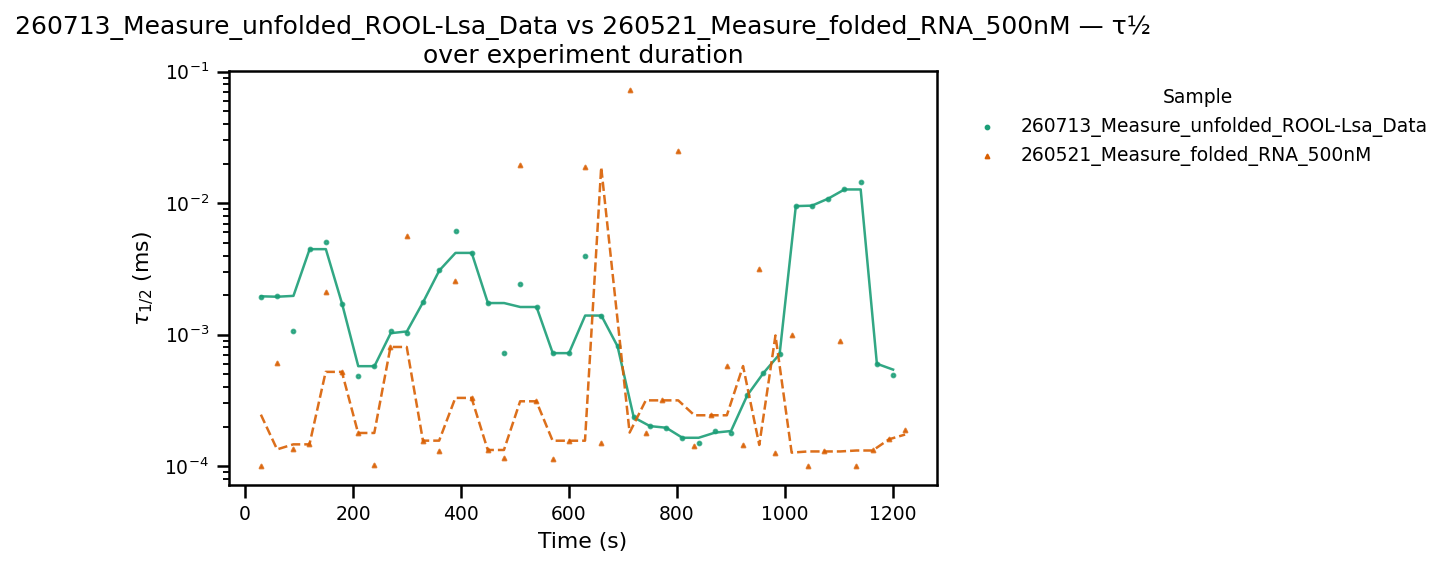

In [62]:
# --- Plot 1: τ½ over experiment duration — Sample 1 vs Sample 2 ---
# Both samples are treated equally: same marker size and alpha

AX_W, AX_H = 12, 7  # axes size in cm

# --- Color coding ---
# 'phase'  : color = phase, marker shape = sample (useful if a file has several phases)
# 'sample' : color = sample (scatter and trendline share one color per sample)
# 'auto'   : 'phase' only if at least one sample contains more than one phase,
#            otherwise 'sample' — avoids a redundant double legend when each file
#            holds a single measurement
COLOR_BY = 'auto'

# --- Sample appearance ---
SAMPLE_MARKERS = {'sample_1': 'o', 'sample_2': '^'}   # marker per sample
SAMPLE_LINESTYLES = {'sample_1': '-', 'sample_2': '--'}  # trendline style per sample

# --- Trendline settings ---
SHOW_TRENDLINE = {'sample_1': True, 'sample_2': True}  # show trendline per sample

# Window size as a percentage of the smaller dataset
# This ensures both trendlines are smoothed equally, regardless of data size
WINDOW_SIZE_PCT = 7.5  # % of the smaller dataset
WINDOW_SIZE = max(1, int(min(len(df[df['sample'] == s]) for s in sample_keys)
                         * WINDOW_SIZE_PCT / 100))

# --- Font and style settings ---
fs = get_fontsizes(AX_W, AX_H,
    title             = 'auto',  # plot title
    label             = 'auto',  # axis labels
    tick              = 'auto',  # tick labels
    legend            = 'auto',  # legend text and title
    marker            = 'auto',  # data point size
    linewidth         = 'auto',  # axes frame line thickness
    tick_length       = 'auto',  # major tick line length
    tick_width        = 'auto',  # major tick line width
    minor_tick_length = 'auto',  # minor tick line length
    minor_tick_width  = 'auto',  # minor tick line width
    trendline_width   = 'auto',  # trendline thickness
)

# Phase colors — shared by both samples so phases stay comparable
cmap = plt.colormaps['tab10']
phase_colors = {phase: cmap(i % 10) for i, phase in enumerate(phase_order)}

# Sample colors — used for the trendlines and for Plot 3
cmap_samples  = plt.colormaps['Dark2']
sample_colors = {s: cmap_samples(i) for i, s in enumerate(sample_keys)}

# Resolve COLOR_BY: which phases does each sample actually contain?
phases_per_sample = {s: [p for p in phase_order
                         if len(df[(df['sample'] == s) & (df['phase'] == p)]) > 0]
                     for s in sample_keys}
if COLOR_BY == 'auto':
    color_by = 'phase' if any(len(p) > 1 for p in phases_per_sample.values()) else 'sample'
else:
    color_by = COLOR_BY

# Point color used by Plot 1 and Plot 2
def point_color(sample, phase):
    return sample_colors[sample] if color_by == 'sample' else phase_colors[phase]

print(f"Color coding: {color_by}")
for s in sample_keys:
    print(f"  {s} ({sample_labels[s]}): phases {phases_per_sample[s]}")

def _plot_comparison(fig, axes):
    ax = axes.flatten()[0]

    for s in sample_keys:
        df_s = df[df['sample'] == s].sort_values('time')

        # Scatter: color per phase or per sample (see COLOR_BY), marker shape per sample
        for phase in phase_order:
            phase_data = df_s[df_s['phase'] == phase]
            if len(phase_data) == 0:
                continue
            ax.scatter(
                phase_data['time'],
                phase_data['tau_half_ms'],
                color=point_color(s, phase),
                marker=SAMPLE_MARKERS[s],
                s=fs['marker'],
                alpha=0.8,
                zorder=2,
            )

        # Trendline: rolling median in log space
        # Uses the shared WINDOW_SIZE so both trendlines are equally smoothed
        if SHOW_TRENDLINE[s] and len(df_s) > 0:
            log_tau = np.log10(df_s['tau_half_ms'])
            trend   = log_tau.rolling(window=WINDOW_SIZE, center=True, min_periods=1).median()
            ax.plot(df_s['time'], 10**trend,
                    color=sample_colors[s], linewidth=fs['trendline_width'],
                    alpha=0.9, zorder=3, linestyle=SAMPLE_LINESTYLES[s])

    # --- Legend ---
    # color_by == 'sample': one entry per sample (color + marker already unique)
    # color_by == 'phase' : phase colors + sample marker shapes listed separately
    if color_by == 'phase':
        for phase in phase_order:
            ax.scatter([], [], color=phase_colors[phase], marker='s',
                       s=fs['marker'], label=phase)
        for s in sample_keys:
            ax.scatter([], [], color='black', marker=SAMPLE_MARKERS[s],
                       s=fs['marker'], label=sample_labels[s])
            if SHOW_TRENDLINE[s]:
                ax.plot([], [], color=sample_colors[s], linewidth=fs['trendline_width'],
                        linestyle=SAMPLE_LINESTYLES[s], label=f'{sample_labels[s]} trend')
        legend_title = 'Phase / Sample'
    else:
        for s in sample_keys:
            ax.scatter([], [], color=sample_colors[s], marker=SAMPLE_MARKERS[s],
                       s=fs['marker'], label=sample_labels[s])
        legend_title = 'Sample'

    ax.set_xlabel('Time (s)', fontsize=fs['label'])
    ax.set_ylabel(r'$\tau_{1/2}$ (ms)', fontsize=fs['label'])
    ax.set_title(f'{sample_labels["sample_1"]} vs {sample_labels["sample_2"]} — τ½ over experiment duration',
                 fontsize=fs['title'], wrap=True)
    ax.tick_params(which='major', labelsize=fs['tick'],
                   length=fs['tick_length'], width=fs['tick_width'])
    ax.tick_params(which='minor',
                   length=fs['minor_tick_length'], width=fs['minor_tick_width'])
    ax.legend(frameon=False, title=legend_title,
              bbox_to_anchor=(1.02, 1), loc='upper left',
              fontsize=fs['legend'], title_fontsize=fs['legend'])
    ax.set_yscale('log')
    for spine in ax.spines.values():
        spine.set_linewidth(fs['linewidth'])

fig, axes = plot_with_fixed_axes(_plot_comparison, n_rows=1, n_cols=1,
                                 ax_width_cm=AX_W, ax_height_cm=AX_H)
plt.show()

In [63]:
# --- Plot 2: τ½ vs Temperature for all temperature-dependent phases ---
# Both samples are treated equally, colors follow COLOR_BY from the Plot 1 cell
# Phases and colors are detected automatically from phase_order and phase_colors
# Font sizes: change 'auto' to a number to override

AX_W, AX_H = 8, 5  # axes size in cm

# --- Trendline settings ---
SHOW_TRENDLINE = {'sample_1': True, 'sample_2': True}  # show trendline per sample

# Window size as a percentage of the smaller phase dataset
# Calculated per phase since each phase has a different number of points
# max(1, ...) ensures the window is at least 1 even for very small datasets
WINDOW_SIZE_PCT = 20  # % of the smaller phase dataset

# --- Font and style settings ---
fs = get_fontsizes(AX_W, AX_H,
    title             = 'auto',  # plot title
    label             = 'auto',  # axis labels
    tick              = 'auto',  # tick labels
    legend            = 'auto',  # legend text and title
    marker            = 'auto',  # data point size
    linewidth         = 'auto',  # axes frame line thickness
    tick_length       = 'auto',  # major tick line length
    tick_width        = 'auto',  # major tick line width
    minor_tick_length = 'auto',  # minor tick line length
    minor_tick_width  = 'auto',  # minor tick line width
    trendline_width   = 'auto',  # trendline thickness
)

# A phase counts as temperature-dependent if its name contains two numbers (e.g. '20-90C')
temp_phases = []
for phase in phase_order:
    temps_in_name = re.findall(r'\d+\.?\d*', phase)
    if len(temps_in_name) >= 2:
        temp_phases.append(phase)

# Skip this plot if no phase is a temperature ramp (e.g. isothermal measurements)
if not temp_phases:
    print("No temperature-dependent phases found — Plot 2 skipped.")
    print(f"Phases present: {phase_order}")

else:
    # Draw one phase into a given axes — used by both the single and the combined plots
    def _draw_phase(ax, phase, show_legend=False):
        temps_in_name = re.findall(r'\d+\.?\d*', phase)
        invert        = float(temps_in_name[0]) > float(temps_in_name[1])

        df_phase = {s: df[(df['sample'] == s) & (df['phase'] == phase)].sort_values('temp')
                    for s in sample_keys}
        window   = max(1, int(min(len(df_phase[s]) for s in sample_keys) * WINDOW_SIZE_PCT / 100))

        for s in sample_keys:
            df_s = df_phase[s]
            if len(df_s) == 0:
                continue
            # Scatter: phase color, marker shape per sample
            ax.scatter(df_s['temp'], df_s['tau_half_ms'],
                       color=point_color(s, phase), marker=SAMPLE_MARKERS[s],
                       s=fs['marker'], alpha=0.8, zorder=2,
                       label=sample_labels[s] if show_legend else None)
            # Trendline: rolling median in log space, sorted by temp
            if SHOW_TRENDLINE[s]:
                log_tau = np.log10(df_s['tau_half_ms'])
                trend   = log_tau.rolling(window=window, center=True, min_periods=1).median()
                ax.plot(df_s['temp'], 10**trend,
                        color=sample_colors[s], linewidth=fs['trendline_width'],
                        alpha=0.9, zorder=3, linestyle=SAMPLE_LINESTYLES[s])

        ax.set_xlabel('Temperature (°C)', fontsize=fs['label'])
        ax.set_ylabel(r'$\tau_{1/2}$ (ms)', fontsize=fs['label'])
        ax.tick_params(which='major', labelsize=fs['tick'],
                       length=fs['tick_length'], width=fs['tick_width'])
        ax.tick_params(which='minor',
                       length=fs['minor_tick_length'], width=fs['minor_tick_width'])
        ax.set_yscale('log')
        if invert:
            ax.invert_xaxis()
        for spine in ax.spines.values():
            spine.set_linewidth(fs['linewidth'])

    # --- Individual plots ---
    for phase in temp_phases:

        def _plot2_single(fig, axes, _phase=phase):
            ax = axes.flatten()[0]
            _draw_phase(ax, _phase, show_legend=True)
            ax.set_title(f'{sample_labels["sample_1"]} vs {sample_labels["sample_2"]} — {_phase}',
                         fontsize=fs['title'], wrap=True)
            ax.legend(frameon=False, title='Sample',
                      bbox_to_anchor=(1.02, 1), loc='upper left',
                      fontsize=fs['legend'], title_fontsize=fs['legend'])

        fig, axes = plot_with_fixed_axes(_plot2_single, n_rows=1, n_cols=1,
                                         ax_width_cm=AX_W, ax_height_cm=AX_H)
        plt.show()

    # --- Combined plot: max 3 per row ---
    n_phases = len(temp_phases)
    n_cols   = min(3, n_phases)
    n_rows   = math.ceil(n_phases / n_cols)

    def _plot2_combined(fig, axes):
        axes_flat = axes.flatten()
        for idx, phase in enumerate(temp_phases):
            ax = axes_flat[idx]
            _draw_phase(ax, phase, show_legend=(idx == 0))
            ax.set_title(f'{phase}', fontsize=fs['title'])
            if idx == 0:
                ax.legend(frameon=False, title='Sample', loc='best',
                          fontsize=fs['legend'], title_fontsize=fs['legend'])
        for idx in range(n_phases, len(axes_flat)):
            axes_flat[idx].set_visible(False)
        fig.suptitle(f'{sample_labels["sample_1"]} vs {sample_labels["sample_2"]} — τ½ vs Temperature',
                     y=1.02, fontsize=fs['title'])

    fig, axes = plot_with_fixed_axes(_plot2_combined, n_rows=n_rows, n_cols=n_cols,
                                     ax_width_cm=AX_W, ax_height_cm=AX_H)
    plt.show()

No temperature-dependent phases found — Plot 2 skipped.
Phases present: ['200nM']


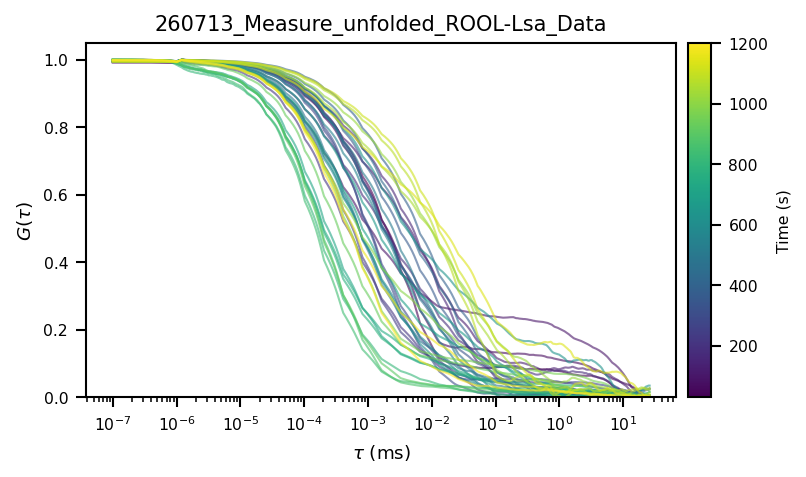

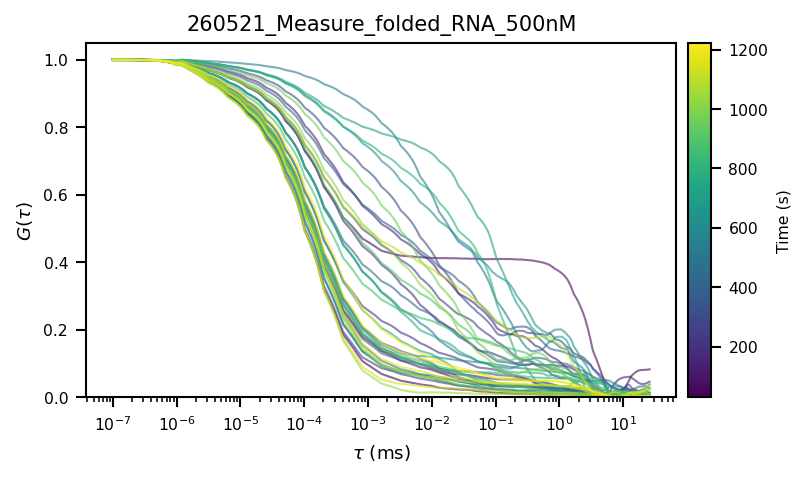

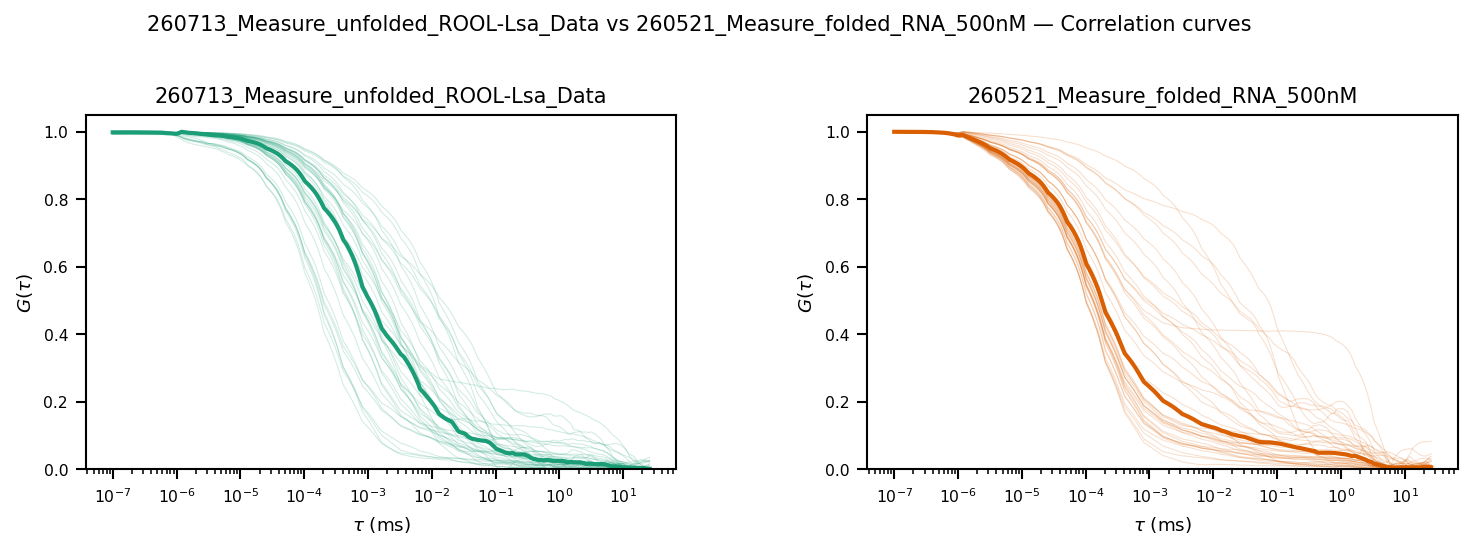

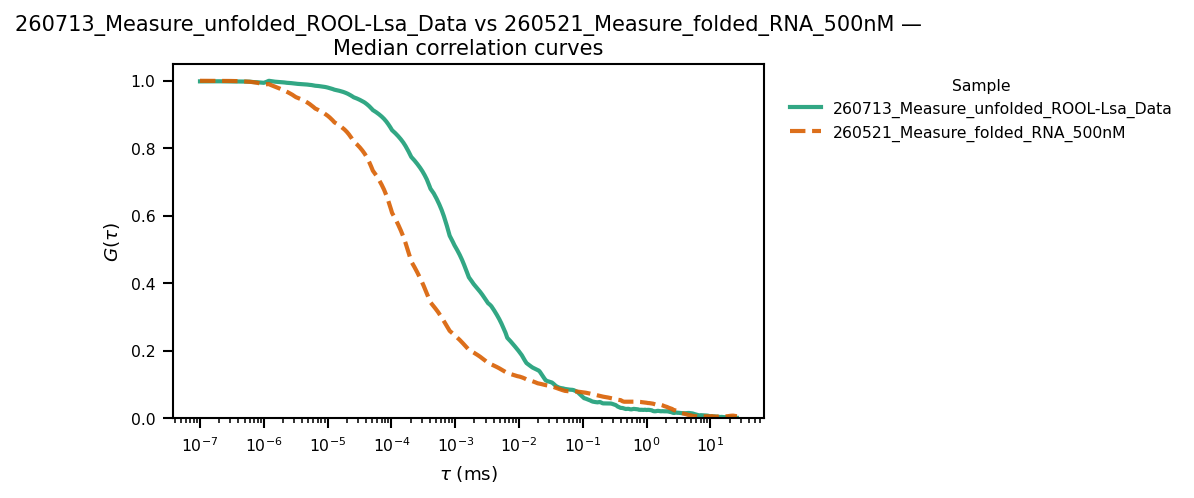

In [64]:
# --- Plot 3: Correlation curves G(τ) vs τ — both samples ---
# Individual plots: all curves per sample, colored by time (viridis)
# Combined plot: median curve + individual curves per sample
# Overlay plot: both median curves overlaid, colored by sample_colors, with legend

AX_W, AX_H = 10, 6  # axes size in cm

# --- Font and style settings ---
fs = get_fontsizes(AX_W, AX_H,
    title             = 'auto',  # plot title
    label             = 'auto',  # axis labels
    tick              = 'auto',  # tick labels
    legend            = 'auto',  # legend text and title
    linewidth         = 'auto',  # curve line thickness
    tick_length       = 'auto',  # major tick line length
    tick_width        = 'auto',  # major tick line width
    minor_tick_length = 'auto',  # minor tick line length
    minor_tick_width  = 'auto',  # minor tick line width
    cbar_width        = 'auto',  # colorbar width in cm
    cbar_fontsize     = 'auto',  # colorbar label and tick size
)

# --- Pre-compute median curves for both samples ---
# Median (not geometric mean) since G(τ) is bounded [0, 1]
median_curves = {}
for sample in sample_keys:
    curves = np.stack(df[df['sample'] == sample]['smoothed'].values)
    median_curves[sample] = np.median(curves, axis=0)

# --- Individual plots: one per sample, curves colored by time ---
for sample in sample_keys:
    sample_data = df[df['sample'] == sample].copy().sort_values('time')
    val_min     = sample_data['time'].min()
    val_max     = sample_data['time'].max()
    cmap_time   = plt.cm.viridis

    def _plot3_single(fig, axes, _data=sample_data, _sample=sample,
                      _val_min=val_min, _val_max=val_max, _cmap=cmap_time):
        ax = axes.flatten()[0]
        for _, row in _data.iterrows():
            norm_val = (row['time'] - _val_min) / (_val_max - _val_min) if _val_max > _val_min else 0.5
            color    = _cmap(norm_val)
            ax.plot(TAU_arr, row['smoothed'], color=color,
                    alpha=0.6, linewidth=fs['linewidth'])
        sm = plt.cm.ScalarMappable(cmap=_cmap,
                                   norm=plt.Normalize(vmin=_val_min, vmax=_val_max))
        add_colorbar_fixed(fig, ax, sm, label='Time (s)',
                           ax_width_cm=AX_W, ax_height_cm=AX_H, fs=fs)
        ax.set_xscale('log')
        ax.set_xlabel(r'$\tau$ (ms)', fontsize=fs['label'])
        ax.set_ylabel(r'$G(\tau)$', fontsize=fs['label'])
        ax.set_title(f'{sample_labels[_sample]}', fontsize=fs['title'], wrap=True)
        ax.tick_params(which='major', labelsize=fs['tick'],
                       length=fs['tick_length'], width=fs['tick_width'])
        ax.tick_params(which='minor',
                       length=fs['minor_tick_length'], width=fs['minor_tick_width'])
        ax.set_ylim(0, 1.05)
        for spine in ax.spines.values():
            spine.set_linewidth(fs['linewidth'])

    fig, axes = plot_with_fixed_axes(_plot3_single, n_rows=1, n_cols=1,
                                     ax_width_cm=AX_W, ax_height_cm=AX_H)
    plt.show()

# --- Combined plot: median curve + individual curves per sample ---
n_samples = len(sample_keys)
n_cols    = min(3, n_samples)
n_rows    = math.ceil(n_samples / n_cols)

def _plot3_combined(fig, axes):
    axes_flat = axes.flatten()
    for idx, sample in enumerate(sample_keys):
        ax          = axes_flat[idx]
        sample_data = df[df['sample'] == sample]
        color       = sample_colors[sample]
        curves      = np.stack(sample_data['smoothed'].values)

        # Plot all individual curves faintly in background
        for curve in curves:
            ax.plot(TAU_arr, curve, color=color, alpha=0.2,
                    linewidth=fs['linewidth'] * 0.5)
        # Plot median curve on top
        ax.plot(TAU_arr, median_curves[sample], color=color, alpha=1.0,
                linewidth=fs['linewidth'] * 2)

        ax.set_xscale('log')
        ax.set_xlabel(r'$\tau$ (ms)', fontsize=fs['label'])
        ax.set_ylabel(r'$G(\tau)$', fontsize=fs['label'])
        ax.set_title(f'{sample_labels[sample]}', fontsize=fs['title'], wrap=True)
        ax.tick_params(which='major', labelsize=fs['tick'],
                       length=fs['tick_length'], width=fs['tick_width'])
        ax.tick_params(which='minor',
                       length=fs['minor_tick_length'], width=fs['minor_tick_width'])
        ax.set_ylim(0, 1.05)
        for spine in ax.spines.values():
            spine.set_linewidth(fs['linewidth'])

    for idx in range(n_samples, len(axes_flat)):
        axes_flat[idx].set_visible(False)
    fig.suptitle(f'{sample_labels["sample_1"]} vs {sample_labels["sample_2"]} — Correlation curves',
                 y=1.02, fontsize=fs['title'])

fig, axes = plot_with_fixed_axes(_plot3_combined, n_rows=n_rows, n_cols=n_cols,
                                 ax_width_cm=AX_W, ax_height_cm=AX_H)
plt.show()

# --- Overlay plot: both median curves in one plot, colored by sample_colors ---
def _plot3_overlay(fig, axes):
    ax = axes.flatten()[0]

    for sample in sample_keys:
        ax.plot(TAU_arr, median_curves[sample],
                color=sample_colors[sample], linewidth=fs['linewidth'] * 2,
                linestyle=SAMPLE_LINESTYLES[sample], alpha=0.9,
                label=sample_labels[sample])

    ax.set_xscale('log')
    ax.set_xlabel(r'$\tau$ (ms)', fontsize=fs['label'])
    ax.set_ylabel(r'$G(\tau)$', fontsize=fs['label'])
    ax.set_title(f'{sample_labels["sample_1"]} vs {sample_labels["sample_2"]} — Median correlation curves',
                 fontsize=fs['title'], wrap=True)
    ax.tick_params(which='major', labelsize=fs['tick'],
                   length=fs['tick_length'], width=fs['tick_width'])
    ax.tick_params(which='minor',
                   length=fs['minor_tick_length'], width=fs['minor_tick_width'])
    ax.legend(frameon=False, title='Sample',
              bbox_to_anchor=(1.02, 1), loc='upper left',
              fontsize=fs['legend'], title_fontsize=fs['legend'])
    ax.set_ylim(0, 1.05)
    for spine in ax.spines.values():
        spine.set_linewidth(fs['linewidth'])

fig, axes = plot_with_fixed_axes(_plot3_overlay, n_rows=1, n_cols=1,
                                 ax_width_cm=AX_W, ax_height_cm=AX_H)
plt.show()

In [1]:
from importlib.util import module_from_spec, spec_from_file_location
import pandas as pd
from IPython.display import display, Image
from types import SimpleNamespace

DATA_FILE_NAME = '20261103_3HAE-annealed_notsure5htb.exp'
data_file = DLS_DIR / 'data' / DATA_FILE_NAME
if not data_file.is_file():
    raise FileNotFoundError(f'Could not find {data_file}')

script_path = DLS_DIR / 'analyze_dls.py'
spec = spec_from_file_location('dls_analysis', script_path)
if spec is None or spec.loader is None:
    raise ImportError(f'Could not load the DLS analysis script at {script_path}')
dls = module_from_spec(spec)
spec.loader.exec_module(dls)

args = SimpleNamespace(
    lag_time_unit='s',
    min_r_squared=0.80,
    scattering_angle_deg=90.0,
    refractive_index=1.333,
    viscosity_pa_s=None,
)
summary, pdi_plot = dls.process_file(data_file, args, PLOT_DIR)
scatter_plot = PLOT_DIR / f'{data_file.stem}_diameter_vs_pdi.png'

summary_table = pd.DataFrame(summary).rename(columns={
    'measurement': 'Sample',
    'acquisitions_total': 'Acquisitions',
    'acquisitions_plotted': 'Scatter points',
    'acquisitions_used': 'Fits accepted',
    'acquisitions_excluded': 'Fits excluded',
    'mean_pdi': 'Mean PDI',
})
summary_table['Median hydrodynamic diameter'] = summary_table['median_diameter_nm'].map(
    lambda value: dls.format_diameter(float(value)) if value != '' else 'n/a'
)
display(summary_table[[
    'Sample', 'Acquisitions', 'Scatter points', 'Fits accepted', 'Fits excluded',
    'Mean PDI', 'Median hydrodynamic diameter',
]])
print('Assumptions: lag times in seconds, 90-degree scattering, n=1.333, and water-like viscosity.')
print(f'Plots saved to: {PLOT_DIR}')
display(Image(filename=str(pdi_plot)))
display(Image(filename=str(scatter_plot)))